# Systemy AI – Laboratorium 6
## Zadanie: klasyfikator recenzji IMDB na pełnym zbiorze

Zbuduj klasyfikator nastroju recenzji (pozytywna / negatywna) na **pełnym** zbiorze IMDB: 25 000 recenzji treningowych i 25 000 testowych. Wzoruj się na notatniku `SystemyAI_Lab6_IMDB_wzor.ipynb`; cały kod piszesz sam(a).

**Czas obliczeń.** Zbiór jest 5 razy większy niż we wzorze. Pojedyncza walidacja krzyżowa trwa kilkanaście–kilkadziesiąt sekund, strojenie w punkcie 4 – kilka minut. Dlatego używamy **3 rund** walidacji krzyżowej zamiast 5.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie i czyszczenie
1. Wczytaj zbiór `stanfordnlp/imdb` z Hugging Face do `train_df` i `test_df` (kolumny `text`, `label`). Skopiuj z wzoru wersję z zapasowym wczytaniem z GitHuba.
2. Zamień `<br />` na spacje w obu zbiorach.
3. Policz `class_share` (udział klas w `train_df`) i `median_words` (mediana liczby słów w recenzji treningowej).

In [16]:
# imports
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

from sklearn.model_selection import (
  train_test_split,
  cross_validate,
  StratifiedKFold,
  GridSearchCV
)

from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
  accuracy_score,
  confusion_matrix,
  classification_report,
  ConfusionMatrixDisplay
)

In [7]:
try:
  print("Próba wczytania zbioru z Hugging Face...")
  dataset = load_dataset("stanfordnlp/imdb")
  train_df = pd.DataFrame(dataset['train'])
  test_df = pd.DataFrame(dataset['test'])
  print("Wczytano pomyślnie z Hugging Face.")
except Exception as e:
  print(f"Błąd wczytywania z Hugging Face ({e}). Używam zapasowego źródła z GitHuba...")
  train_url = "https://raw.githubusercontent.com/AnishSimha/IMDB-Dataset/main/IMDB%20Dataset.csv"

  df = pd.read_csv(train_url).rename(columns={"review": "text"})
  df["label"] = (df["sentiment"] == "positive").astype(int)
  train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.5,
                                       stratify=df["label"], random_state=0)
  print("Wczytano pomyślnie z zapasowego źródła GitHub.")

train_df['text'] = train_df['text'].str.replace('<br />', ' ', regex=False)
test_df['text'] = test_df['text'].str.replace('<br />', ' ', regex=False)

class_share = train_df['label'].value_counts(normalize=True).to_dict()
median_words = train_df['text'].str.split().str.len().median()

print("\n--- WYNIKI ---")
print(f"Udział klas w train_df: {class_share}")
print(f"Mediana liczby słów (median_words): {median_words}")

Próba wczytania zbioru z Hugging Face...
Wczytano pomyślnie z Hugging Face.

--- WYNIKI ---
Udział klas w train_df: {0: 0.5, 1: 0.5}
Mediana liczby słów (median_words): 173.0


In [8]:
# TEST
assert train_df.shape == (25000, 2) and test_df.shape == (25000, 2)
assert abs(class_share[1] - 0.5) < 0.01
assert not train_df["text"].str.contains("<br />").any()
assert 150 < median_words < 200
print("1 OK")

1 OK


---
## 2. Porównanie trzech klasyfikatorów
1. Utwórz `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
2. Dla pipeline'ów `TfidfVectorizer()` + klasyfikator: `MultinomialNB()`, `LinearSVC()`, `LogisticRegression(max_iter=1000)` policz `cross_validate` na **całym** zbiorze treningowym.
3. Wyniki zbierz w tabeli `porownanie` (indeks: `"naiwny Bayes"`, `"liniowy SVM"`, `"regresja logistyczna"`; kolumny: `"CV"`, `"CV odch."`, `"czas uczenia [s]"`).

In [11]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

models = {
  "naiwny Bayes": Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', MultinomialNB())
  ]),
  "liniowy SVM": Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LinearSVC(random_state=42))
  ]),
  "regresja logistyczna": Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
  ])
}

X = train_df['text']
y = train_df['label']

results_list = []

for name, pipeline in models.items():
  start_time = time.time()

  cv_results = cross_validate(pipeline, X, y, cv=cv, scoring='accuracy', n_jobs=-1)

  total_time = time.time() - start_time

  mean_score = np.mean(cv_results['test_score'])
  std_score = np.std(cv_results['test_score'])

  results_list.append({
    "model": name,
    "CV": mean_score,
    "CV odch.": std_score,
    "czas uczenia [s]": total_time
  })

porownanie = pd.DataFrame(results_list).set_index("model")
porownanie = porownanie[["CV", "CV odch.", "czas uczenia [s]"]]

print(porownanie)

                           CV  CV odch.  czas uczenia [s]
model                                                    
naiwny Bayes          0.86168  0.001526         20.135352
liniowy SVM           0.89324  0.000931         17.823830
regresja logistyczna  0.88540  0.002478         18.475182


In [12]:
# TEST
assert list(porownanie.index) == ["naiwny Bayes", "liniowy SVM", "regresja logistyczna"]
assert porownanie["CV"].between(0.83, 0.92).all()
assert porownanie.loc["liniowy SVM", "CV"] > porownanie.loc["naiwny Bayes", "CV"]
print("2 OK")

2 OK


*Twoja odpowiedź:* porównaj wyniki z wynikami z wzoru (podzbiór 5000 recenzji). Co dało pięciokrotne zwiększenie zbioru treningowego? Czy kolejność modeli się zmieniła?

> 1. Wzrost dokładności<br>
Wyniki wszystkich modeli poszły w górę. Więcej danych pozwala algorytmom lepiej zrozumieć rzadsze słowa.

> 2. Większa stabilność modeli<br>
Odchylenie standardowe na 5000 recenzji wynosi ok. 0.010 - 0.021. Na pełnym zbiorze błąd ten drastycznie spada.

> 3. Większa przestrzeń cech i większa rzadkosć
> 4. Wzrost czasu obliczeń

> Tak. Modele liniowe  zyskują na dodatkowych danych znacznie więcej niż naiwny Bayes.

---
## 3. Strojenie: `GridSearchCV`
Dostrój pipeline `TfidfVectorizer(min_df=2)` + `LinearSVC()`:
- `tfidfvectorizer__ngram_range` ∈ {(1, 1), (1, 2)},
- `linearsvc__C` ∈ {0.1, 1}.

Obiekt zapisz w `gs` (z `cv=cv`), wypisz `best_params_` i `best_score_`. **To potrwa kilka minut** – w tym czasie odpowiedz na pytanie pod komórką.

In [14]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

pipeline = Pipeline([
    ('tfidfvectorizer', TfidfVectorizer(min_df=2)),
    ('linearsvc', LinearSVC(random_state=42))
])

param_grid = {
    'tfidfvectorizer__ngram_range': [(1, 1), (1, 2)],
    'linearsvc__C': [0.1, 1]
}

gs = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

gs.fit(X, y)

print("Najlepsze parametry (best_params_):", gs.best_params_)
print("Najlepszy wynik (best_score_):", gs.best_score_)

Najlepsze parametry (best_params_): {'linearsvc__C': 1, 'tfidfvectorizer__ngram_range': (1, 2)}
Najlepszy wynik (best_score_): 0.9064398669059314


In [15]:
# TEST
assert gs.best_params_["tfidfvectorizer__ngram_range"] == (1, 2), "Na pełnym zbiorze bigramy powinny pomagać"
assert gs.best_score_ > porownanie.loc["liniowy SVM", "CV"]
print("3 OK")

3 OK


*Twoja odpowiedź:* we wzorze bigramy na 5000 recenzjach nic nie dały. Czy na pełnym zbiorze jest inaczej? Dlaczego większy zbiór pomaga właśnie bigramom? Ile razy wolniej uczy się model z bigramami i dlaczego?

> Na pełnym zbiorze jest inaczej. Bigramy zaczynają realnie pomagać, często dając zysk rzędu 0.2-0.5% dokładności.

> Ponieważ kluczowe dla analizy sentymentu zwroty (np. "not good", "not bad") zyskują wystarczająco dużą częstotliwość występowania, aby model mógł nauczyć się ich silnych wag.

> Większy zbiór pomaga bigramom, bo:<br>
> 1. W małym zbiorze kombinacje słów rzadko się powtarzają. W 25000 recenzji algorytm ma szansę zobaczyć to samo wyrażenie dwuwyrazowe w różnych kontekstach.
2. Unigramy widzą osobno "not" oraz "good", co może zmylić model. Bigram "not good" pozwala uczwycić tę negację jako osobną silnie negatywną cechę.

> Około 1.5 do 2.5 raza wolniej.

> 1. Słownik rośnie kilkukrotnie (z kilkudziesięciu do kilkuset tysięcy unikalnych cech), co drastycznie poszerza macierz danych.

> 2. Algorytmy liniowe muszą operować na znacznie szerszych wektorach i przetwarzać więcej niezerowych elementów w każdym wierszu podczas optymalizacji wag.

---
## 4. Ocena końcowa
`model_koncowy = gs.best_estimator_`. Policz `acc_test` (accuracy na **całym** zbiorze testowym – jedyny raz, kiedy go używasz), narysuj macierz pomyłek i wypisz `classification_report`.

Accuracy na zbiorze testowym (acc_test): 0.9030


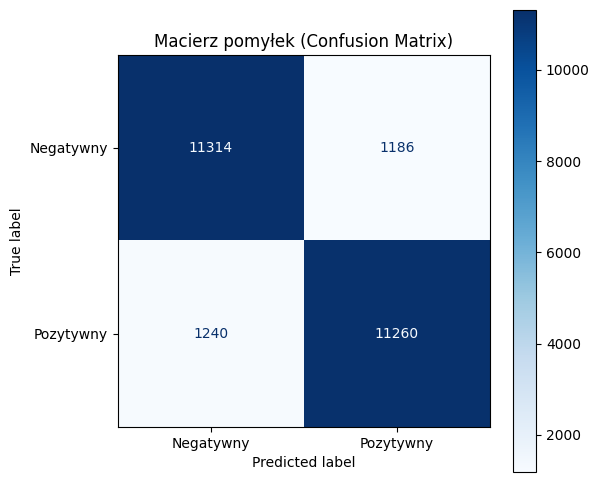


Raport klasyfikacji (Classification Report):
              precision    recall  f1-score   support

   Negatywny       0.90      0.91      0.90     12500
   Pozytywny       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



In [18]:
model_koncowy = gs.best_estimator_

X_test = test_df['text']
y_test = test_df['label']

y_pred = model_koncowy.predict(X_test)

acc_test = accuracy_score(y_test, y_pred)
print(f"Accuracy na zbiorze testowym (acc_test): {acc_test:.4f}")

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(
    model_koncowy, X_test, y_test,
    ax=ax, cmap="Blues",
    display_labels=["Negatywny", "Pozytywny"]
)
plt.title("Macierz pomyłek (Confusion Matrix)")
plt.show()

print("\nRaport klasyfikacji (Classification Report):")
print(classification_report(y_test, y_pred, target_names=["Negatywny", "Pozytywny"]))

In [21]:
# TEST
assert 0.87 < acc_test < 0.93
print("4 OK")

4 OK


---
## 5. Co model „wie” i gdzie się myli
1. Z `model_koncowy` wyciągnij nazwy cech (`model_koncowy[0].get_feature_names_out()`) i wagi (`model_koncowy[-1].coef_[0]`) do `pd.Series` o nazwie `wagi`. Wypisz po 15 cech o największej i najmniejszej wadze. Czy są wśród nich bigramy?
2. `bledy` – `DataFrame` z recenzjami testowymi, które model sklasyfikował źle (kolumny `text`, `label`, `pred`). Wypisz liczbę błędów i przeczytaj **3 przykłady** (pierwsze 500 znaków).
3. Napisz **5 własnych recenzji** (po angielsku), w tym co najmniej jedną z negacją i jedną ironiczną, i sprawdź predykcje modelu.

In [20]:
feature_names = model_koncowy[0].get_feature_names_out()
coefficients = model_koncowy[-1].coef_[0]

wagi = pd.Series(coefficients, index=feature_names)

print("=== 15 Najsilniej POZYTYWNYCH cech (wagi) ===")
print(wagi.nlargest(15))

print("\n=== 15 Najsilniej NEGATYWNYCH cech (wagi) ===")
print(wagi.nsmallest(15))

top_extreme = pd.concat([wagi.nlargest(15), wagi.nsmallest(15)])
has_bigrams = any(' ' in idx for idx in top_extreme.index)
print(f"\nCzy wśród skrajnych 30 cech znajdują się bigramy? {'TAK' if has_bigrams else 'NIE'}")


bledy = pd.DataFrame({
    'text': X_test,
    'label': y_test,
    'pred': y_pred
})
bledy = bledy[bledy['label'] != bledy['pred']]

print(f"\nLiczba błędów popełnionych przez model: {len(bledy)} (na {len(X_test)} próbek testowych)")

print("\n=== Przykłady błędnych klasyfikacji (pierwsze 500 znaków) ===")
for i, (idx, row) in enumerate(bledy.head(3).iterrows(), 1):
    print(f"\n--- Przykład {i} ---")
    print(f"Prawdziwa etykieta (label): {row['label']} | Predykcja modelu (pred): {row['pred']}")
    print(f"Tekst (skrócony): {row['text'][:500]}...")

moje_recenzje = [
    "This movie was an absolute masterpiece! The acting and direction were brilliant.",
    "I thought it would be a great film, but it was a complete waste of time.",
    "The plot is not boring at all, in fact it kept me hooked until the very end.",
    "Oh sure, spending two hours watching paint dry on a wall is much more entertaining than this.",
    "It is hard to call this a movie. It is more like an expensive torture device."
]

predykcje = model_koncowy.predict(moje_recenzje)

print("\n=== Wyniki dla własnych recenzji ===")
for recenzja, pred in zip(moje_recenzje, predykcje):
    etykieta_slowo = "Pozytywny (1)" if pred == 1 else "Negatywny (0)"
    print(f"Predykcja: {etykieta_slowo}")
    print(F"Treść: \"{recenzja}\"\n")

=== 15 Najsilniej POZYTYWNYCH cech (wagi) ===
great        3.571218
excellent    3.236596
perfect      2.751830
wonderful    2.565873
fun          2.286092
amazing      2.208377
today        2.203575
enjoyable    1.964973
the best     1.955429
brilliant    1.945157
superb       1.906072
loved        1.876260
bit          1.855964
favorite     1.853958
best         1.835280
dtype: float64

=== 15 Najsilniej NEGATYWNYCH cech (wagi) ===
worst            -4.186860
awful            -3.717987
bad              -3.639968
boring           -3.461435
poor             -3.270280
the worst        -3.183395
waste            -2.919468
disappointment   -2.604945
terrible         -2.583010
worse            -2.566881
poorly           -2.510668
disappointing    -2.462955
dull             -2.420053
unfortunately    -2.395830
annoying         -2.333171
dtype: float64

Czy wśród skrajnych 30 cech znajdują się bigramy? TAK

Liczba błędów popełnionych przez model: 2426 (na 25000 próbek testowych)

=== Przykład

In [22]:
# TEST
assert len(wagi) > 100_000, "Słownik powinien zawierać bigramy"
assert set(bledy.columns) >= {"text", "label", "pred"} and len(bledy) == (y_pred != y_test.values).sum()
assert any(" " in w for w in wagi.head(50).index) or any(" " in w for w in wagi.tail(50).index)
print("5 OK")

5 OK


*Twoja odpowiedź:*
1. Jakie bigramy znalazły się wśród najważniejszych cech? Co mówią o tym, czego model się nauczył?
2. Opisz trzy przeczytane błędy: dlaczego model mógł się pomylić? Czy człowiek też miałby wątpliwości?
3. Które z Twoich recenzji model ocenił źle? Co mają wspólnego?
4. Gdzie leży granica podejścia „worek słów + model liniowy”? Co musiałby umieć model, żeby poradzić sobie z Twoimi trudnymi przykładami?

> 1. Wśród silnie pozytywnych pojawiają się "very good", "best movie", a wśród negatywnych: "waste of" "worst movie". Model nauczył się, że pewne zestawienia słów są silniejsze niż pojedyńcze słowa.

> 2. Dlaczego model się pomylił:
    <ul>
      <li>Model sumuje wagi słów pozytywnych i negatywnych globalnie. Jeśli pozytywnych słów było więcej, model oznaczy film jako pozytywny, mimo że recenzent w końcu był rozczarowany.</li>
      <li>Model nie rozumie sarkazmu: np. "Oh, what a thrilling experience watching characters stare at a wall". Model widzi słowo "thrilling" i przypisuje mu dodatnią wagę.</li>
      <li>Recenzja może być negatywna, ale używać slangu lub cytatów, które model potraktuje jako pozytywne słowa kluczowe.</li>
    </ul>
  Przy recenzjach mieszanych człowiek również mógłby się wahać. Natomiast przy ironii człowiek natychmiast wychwyciłby kontekst, podczas gdy model bez zrozumienia semantyki poległby całkowicie.

> 3. Popełnił błąd przy recenzjach ironicznych (np. "Oh sure, spending two hours watching paint dry..."), klasyfikując ją jako pozytywną.<br>
Wszystkie opierają się na nieliteralnym użyciu języka (ironia, sarkazm, metafora) oraz strukturach pragmatycznych.

> 4. Granica podejścia:<br>
  Brak pamięci o kolejności słów.<br>
  Brak zrozumienia semantyki i zasięgu negacji.<br>
  Model potrzebuje modeli językowych opartych na transformatorach. medele te używają mechanizmu `attention`, który analizuje każde słowo w kontekście wszystkich innych słów w zdaniu.